# Part 3: Can we predict a learner's native language from which grammar questions they get right or wrong?

If learners from different language backgrounds make different kinds of grammar mistakes, a model should be able to guess a learner's native language from their answers alone. We test this on learners whose single native language is one of the 10 most common in the dataset.

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TUNE_SIZE = 50_000

## 1. Load Data from Parquet File
This file contains learners who list exactly one native language, restricted to the 10 most common languages. Each row has:
- **95 scored questions** (`q...`): the grammar decisions the original authors used to compute the overall score, where native speakers reliably agree. 1 = right, 0 = wrong.
- **37 extra questions** (`d_q...`): the remaining grammar decisions the authors left out of the score because native speakers disagree on them. Like the scored questions, each is coded 0 or 1.
- `native_lang`: the outcome we want to predict.

In [2]:
# Use the version of the file that includes the 37 d_q columns.
DATA_FILE = "clean_native_lang_132.parquet"

df = pd.read_parquet(DATA_FILE)

print(f"Dataset shape: {df.shape}")
print(df["native_lang"].value_counts())

Dataset shape: (223288, 134)
native_lang
Finnish       39787
Turkish       36070
German        24405
Russian       22680
Hungarian     22010
Polish        18541
Dutch         17793
Swedish       16271
Spanish       15555
Portuguese    10176
Name: count, dtype: int64


## 2. Define Predictor Variables and Outcome Variable
We keep the two groups of questions separate so we can compare models trained on the 95 scored questions alone against models trained on all 132.

In [3]:
q_cols = [c for c in df.columns if c.startswith("q")]      # 95 scored questions
d_cols = [c for c in df.columns if c.startswith("d_q")]    # 37 extra questions
all_cols = q_cols + d_cols

print(f"Scored questions: {len(q_cols)} | extra questions: {len(d_cols)} | total: {len(all_cols)}")
print("Missing values in any question column:", int(df[all_cols].isna().sum().sum()))
print("Values in question columns:", sorted(pd.unique(df[all_cols].values.ravel())))

X = df[all_cols].astype(int)
y = df["native_lang"]
languages = sorted(y.unique())

Scored questions: 95 | extra questions: 37 | total: 132
Missing values in any question column: 0
Values in question columns: [np.float64(0.0), np.float64(1.0)]


## 3. Data Exploration
### Class balance
The 10 languages have very different sample sizes, so we use **macro F1** (every language counts equally) as our main metric and class weights where the model supports them.

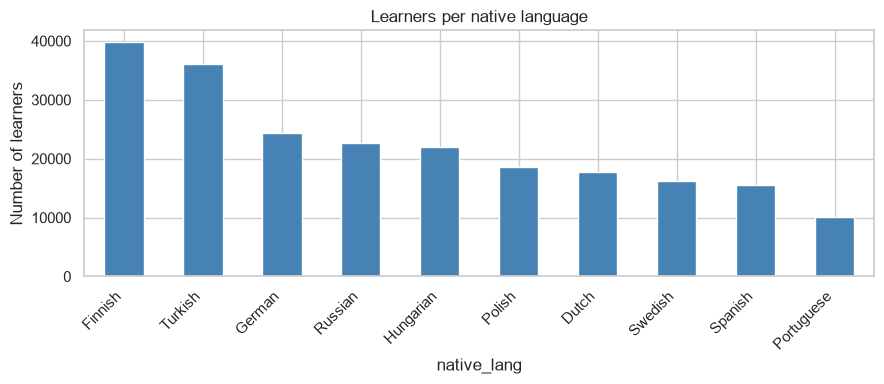

Largest / smallest class: 3.9x


In [4]:
y.value_counts().plot.bar(color="steelblue", figsize=(9, 4))
plt.ylabel("Number of learners")
plt.title("Learners per native language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Largest / smallest class: {y.value_counts().max() / y.value_counts().min():.1f}x")

### Overall score by native language
The overall score is the share of the 95 scored questions answered correctly. If some languages score much higher than others, a model could partly identify native language from *skill level* rather than from language-specific mistakes. We come back to this in Section 11.

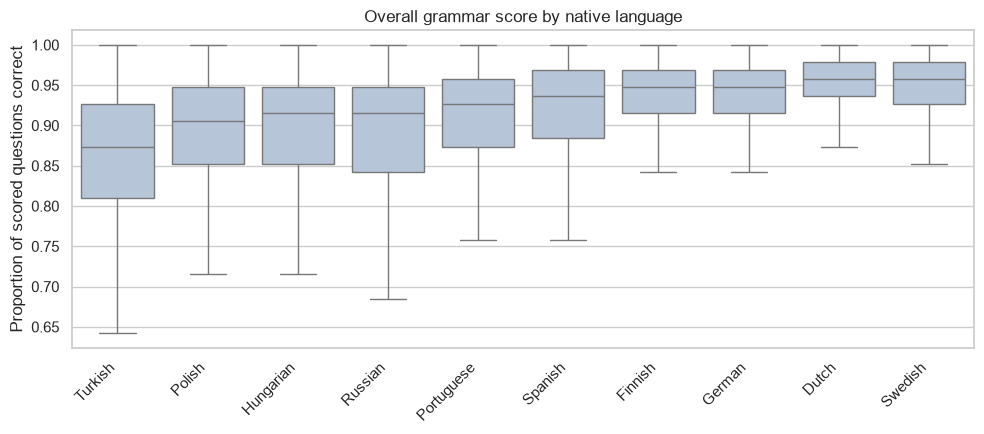

In [5]:
score = X[q_cols].mean(axis=1)

order = score.groupby(y).median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(x=y, y=score, order=order, showfliers=False, color="lightsteelblue")
plt.xlabel("")
plt.ylabel("Proportion of scored questions correct")
plt.title("Overall grammar score by native language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Which questions differ most between languages?
For each question, we compute the share of each language group that answered 1 (for scored questions, the correct answer), then show the 20 questions where the languages differ the most. Bright and dark cells in the same column mean that question separates languages.

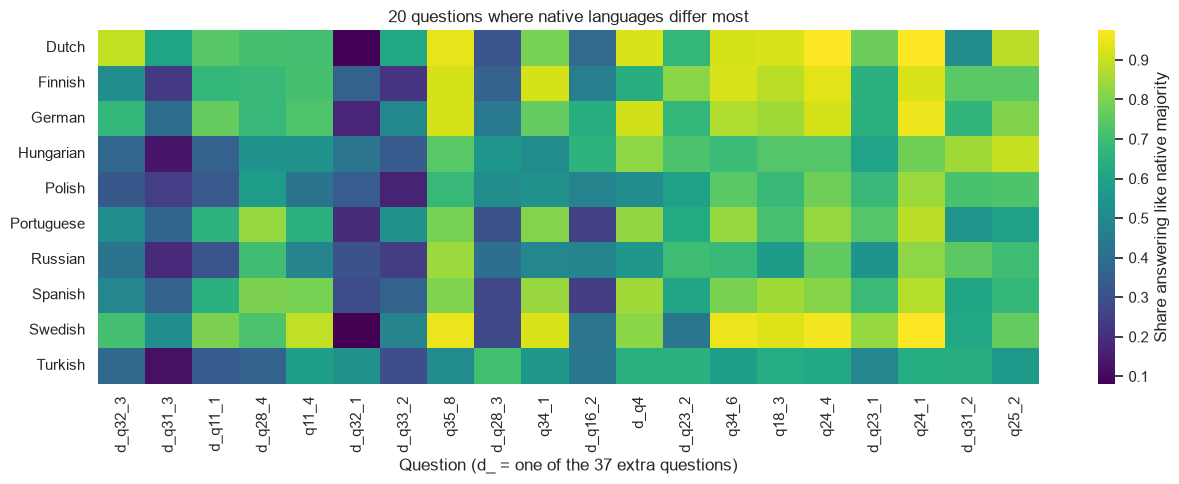

Of these 20 questions, 12 are extra (d_) questions.


In [25]:
rate_by_lang = X.groupby(y).mean()                     # languages x questions
spread = rate_by_lang.max() - rate_by_lang.min()
top_q = spread.sort_values(ascending=False).head(20).index

plt.figure(figsize=(13, 5))
sns.heatmap(rate_by_lang[top_q], cmap="viridis", annot=False, cbar_kws={"label": "Share answering like native majority"})
plt.title("20 questions where native languages differ most")
plt.xlabel("Question (d_ = one of the 37 extra questions)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Of these 20 questions,", sum(c.startswith("d_") for c in top_q), "are extra (d_) questions.")

**Result:** 12 of the 20 questions that differ most between languages are extra (`d_`) questions, an early sign that the questions native speakers disagree on carry the most native-language information.

## 4. Split Data into Training and Test Data
We split into 80% training and 20% test data, stratified by language. For hyperparameter tuning we use a stratified sample of 50,000 training rows, since the full training set is large. The test set is only used for the final evaluation.

Both feature sets (95 and 132 questions) use the **same rows** in each split, so their results are directly comparable.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNE_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Tuning sample: {X_tune.shape}")

Training set: (178630, 132)
Test set: (44658, 132)
Tuning sample: (50000, 132)


## 5. Baseline
A model that always guesses the most common language (Finnish). Every real model has to beat this.

In [8]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f"Baseline accuracy: {accuracy_score(y_test, baseline_pred):.3f}")
print(f"Baseline macro F1: {f1_score(y_test, baseline_pred, average='macro'):.3f}")

Baseline accuracy: 0.178
Baseline macro F1: 0.030


## 6. Models and Hyperparameter Tuning
We compare five models from different families:
- **Logistic regression** (multinomial, one linear score per language)
- **Naive Bayes** (`BernoulliNB`, designed for 0/1 features)
- **Random forest** (bagging ensemble of trees)
- **Gradient boosting** (`HistGradientBoostingClassifier`, a boosting ensemble that is fast on large data)
- **MLP** (a small neural network with one or two hidden layers)

All questions are already 0/1, so no scaling or encoding is needed. Each model is tuned with GridSearchCV using 3-fold stratified cross-validation on the tuning sample, scored by macro F1. Naive Bayes and the MLP have no `class_weight` option; for Naive Bayes, `fit_prior=False` treats all languages as equally likely beforehand instead.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ),
    "Naive Bayes": BernoulliNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "MLP": MLPClassifier(
        early_stopping=True,
        max_iter=200,
        random_state=RANDOM_STATE
    )
}

# Hyperparameters to test.
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10]
    },
    "Naive Bayes": {
        "alpha": [0.01, 0.1, 1.0],
        "fit_prior": [True, False]
    },
    "Random Forest": {
        "max_depth": [None, 20],
        "min_samples_leaf": [1, 5],
        "max_features": ["sqrt", 0.3]
    },
    "Gradient Boosting": {
        "learning_rate": [0.05, 0.1],
        "max_depth": [None, 6]
    },
    "MLP": {
        "hidden_layer_sizes": [(64,), (128,), (128, 64)],
        "alpha": [1e-4, 1e-3]
    }
}

In [10]:
# Cross-validation loop on the stratified tuning sample.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

best_models = {}
tuning_results = []

for name, model in models.items():

    print(f"\nTuning {name}")
    start = time.time()

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV macro F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"Best CV macro F1: {search.best_score_:.4f}")
    print(f"Best parameters: {search.best_params_}")
    print(f"Time: {time.time() - start:.0f}s")


Tuning Logistic Regression
Best CV macro F1: 0.4831
Best parameters: {'C': 0.1}
Time: 16s

Tuning Naive Bayes
Best CV macro F1: 0.3977
Best parameters: {'alpha': 0.01, 'fit_prior': False}
Time: 1s

Tuning Random Forest


/Users/shreyarastogi/Desktop/CS363M/Final_ML_Project/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best CV macro F1: 0.4528
Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Time: 50s

Tuning Gradient Boosting
Best CV macro F1: 0.4981
Best parameters: {'learning_rate': 0.05, 'max_depth': 6}
Time: 104s

Tuning MLP
Best CV macro F1: 0.4989
Best parameters: {'alpha': 0.001, 'hidden_layer_sizes': (128,)}
Time: 12s


In [11]:
# Display the best parameters.
tuning_df = pd.DataFrame(tuning_results).sort_values(by="Best CV macro F1", ascending=False)
display(tuning_df)

,Model,Best CV macro F1,Best Parameters
4,MLP,0.498935,"{'alpha': 0.001, 'hidden_layer_sizes': (128,)}"
3,Gradient Boosting,0.498109,"{'learning_rate': 0.05, 'max_depth': 6}"
0,Logistic Regression,0.483117,{'C': 0.1}
2,Random Forest,0.452836,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
1,Naive Bayes,0.397702,"{'alpha': 0.01, 'fit_prior': False}"


In [12]:
# Retrain each tuned model on the full training set.
final_models = {}

for name, best_model in best_models.items():
    start = time.time()
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
    final_models[name] = final_model
    print(f"{name} retrained in {time.time() - start:.0f}s")

Logistic Regression retrained in 11s
Naive Bayes retrained in 0s
Random Forest retrained in 28s
Gradient Boosting retrained in 66s
MLP retrained in 8s


## 7. Ensemble: Soft Voting
A soft-voting ensemble averages the predicted probabilities of several models, so when one model is unsure the others can outvote it. We combine the three strongest models from cross-validation.

In [13]:
top3 = tuning_df["Model"].head(3).tolist()
print("Voting ensemble uses:", top3)

voting = VotingClassifier(
    estimators=[(name, clone(best_models[name])) for name in top3],
    voting="soft",
    n_jobs=-1
)
voting.fit(X_train, y_train)
final_models["Voting Ensemble"] = voting

Voting ensemble uses: ['MLP', 'Gradient Boosting', 'Logistic Regression']


## 8. Model Evaluation
We compare the models on the test set. Macro F1 is the main metric; precision and recall are also macro-averaged over the 10 languages.

In [14]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

predictions = {name: model.predict(X_test) for name, model in final_models.items()}

evaluation_results = [evaluate("Baseline (most frequent)", y_test, baseline_pred)]
evaluation_results += [evaluate(name, y_test, pred) for name, pred in predictions.items()]

results_df = pd.DataFrame(evaluation_results).sort_values(by="Macro F1", ascending=False)
display(results_df.round(4))

best_name = results_df.iloc[0]["Model"]
best_model = final_models[best_name]
best_pred = predictions[best_name]
print(f"Best model: {best_name}")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
6,Voting Ensemble,0.5577,0.5298,0.5343,0.5308
5,MLP,0.5609,0.5418,0.5214,0.5270
4,Gradient Boosting,0.5462,0.5198,0.5330,0.5233
1,Logistic Regression,0.5160,0.4913,0.5054,0.4939
3,Random Forest,0.5020,0.4770,0.4757,0.4720
2,Naive Bayes,0.4260,0.4168,0.4077,0.3959
0,Baseline (most frequent),0.1782,0.0178,0.1000,0.0302


Best model: Voting Ensemble


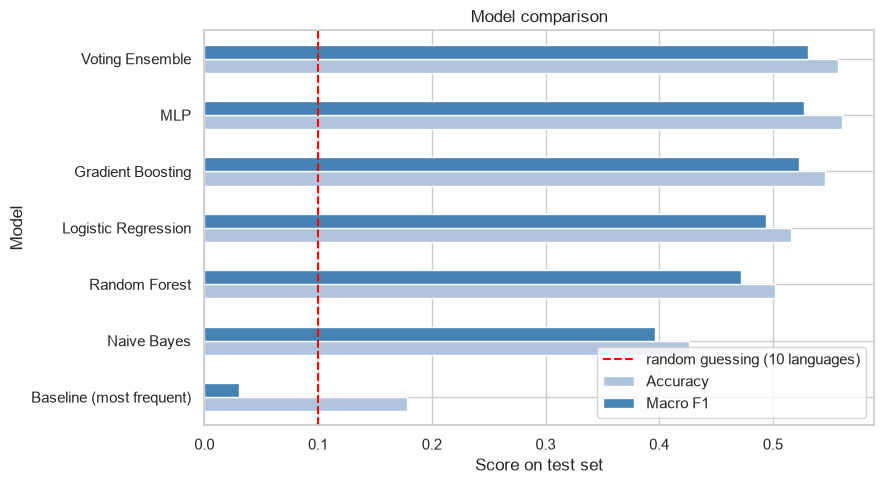

In [15]:
plot_df = results_df.set_index("Model")[["Accuracy", "Macro F1"]].sort_values("Macro F1")
plot_df.plot.barh(figsize=(9, 5), color=["lightsteelblue", "steelblue"])
plt.axvline(0.1, color="red", ls="--", label="random guessing (10 languages)")
plt.xlabel("Score on test set")
plt.title("Model comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result:** Every model beats the baseline by a wide margin. The voting ensemble is best (macro F1 0.531, accuracy 55.8%), but only slightly ahead of the MLP (0.527) and gradient boosting (0.523), so combining models added little. The MLP has the highest accuracy but lower macro F1, since it has no class weighting and leans toward the larger languages. Naive Bayes is weakest (0.396), likely because it assumes each question is independent of the others given the language.

## 9. Feature Experiments
### 9a. 95 scored questions vs. all 132 questions
The original authors removed 37 grammar decisions from the score because native speakers disagree on them. Those items capture dialect and usage variation, so they may carry native-language information that the 95 "standard" questions do not. We retrain the tuned models using only the 95 scored questions, on the same rows, and compare.

,Model,Features,Accuracy,Macro F1
0,Logistic Regression,95 scored questions,0.3972,0.3803
1,Logistic Regression,All 132 questions,0.5160,0.4939
2,Gradient Boosting,95 scored questions,0.4163,0.3971
3,Gradient Boosting,All 132 questions,0.5462,0.5233


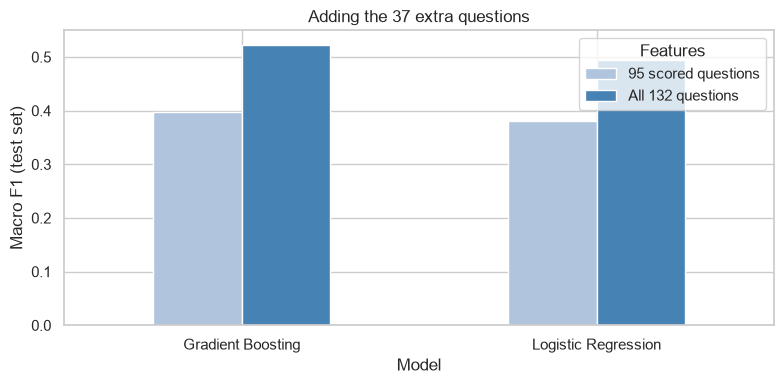

In [16]:
compare_models = ["Logistic Regression", "Gradient Boosting"]
feature_set_results = []

for name in compare_models:
    for label, cols in [("95 scored questions", q_cols), ("All 132 questions", all_cols)]:
        if cols is all_cols:
            pred = predictions[name]
        else:
            model_95 = clone(best_models[name]).fit(X_train[cols], y_train)
            pred = model_95.predict(X_test[cols])
        feature_set_results.append({
            "Model": name,
            "Features": label,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro F1": f1_score(y_test, pred, average="macro")
        })

feature_set_df = pd.DataFrame(feature_set_results)
display(feature_set_df.round(4))

feature_set_df.pivot(index="Model", columns="Features", values="Macro F1").plot.bar(
    figsize=(8, 4), color=["lightsteelblue", "steelblue"])
plt.ylabel("Macro F1 (test set)")
plt.title("Adding the 37 extra questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Result:** Adding the 37 extra questions raised macro F1 by about 0.11–0.13 for both models (logistic regression 0.380 → 0.494; gradient boosting 0.397 → 0.523). This is the largest improvement in the project: the questions left out of the score because native speakers disagree on them are the most informative about a learner's native language.

### 9b. Adding skill information
Two more ideas, compared with cross-validation on the tuning sample (not the test set):
- **+ score:** add each learner's overall score as an extra feature.
- **Skill-adjusted:** replace each answer with *(actual answer − expected answer for someone at the same skill level)*, so the model focuses on language-specific mistakes rather than on how good the learner is overall.

Both are written as scikit-learn transformers inside a pipeline, so the "expected" values are learned only from the training folds.

In [17]:
class AddScore(BaseEstimator, TransformerMixin):
    """Adds each person's overall score (share of the 95 scored questions right) as an extra column."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["score"] = X[q_cols].mean(axis=1)
        return X

class SkillAdjust(BaseEstimator, TransformerMixin):
    """Replaces each answer with (actual - expected for someone at that skill level), plus the score."""
    def __init__(self, n_bands=10):
        self.n_bands = n_bands
    def fit(self, X, y=None):
        score = X[q_cols].mean(axis=1)
        self.edges_ = np.unique(np.quantile(score, np.linspace(0, 1, self.n_bands + 1)))
        band = self._band(score)
        self.expected_ = X.groupby(band).mean().reindex(range(len(self.edges_) - 1)).fillna(X.mean())
        return self
    def _band(self, score):
        return np.clip(np.searchsorted(self.edges_, score, side="right") - 1, 0, len(self.edges_) - 2)
    def transform(self, X):
        score = X[q_cols].mean(axis=1)
        out = pd.DataFrame(X.values - self.expected_.values[self._band(score)], columns=X.columns, index=X.index)
        out["score"] = score
        return out

skill_results = []
for name in compare_models:
    base = best_models[name]
    for label, pipe in [("Plain", clone(base)),
                        ("+ score", make_pipeline(AddScore(), clone(base))),
                        ("Skill-adjusted", make_pipeline(SkillAdjust(), clone(base)))]:
        scores = cross_val_score(pipe, X_tune, y_tune, cv=cv, scoring="f1_macro", n_jobs=-1)
        skill_results.append({"Model": name, "Features": label, "CV macro F1": scores.mean()})

display(pd.DataFrame(skill_results).pivot(index="Model", columns="Features", values="CV macro F1").round(4))

Features,+ score,Plain,Skill-adjusted
Model,,,
Gradient Boosting,0.4988,0.4981,0.4911
Logistic Regression,0.4829,0.4831,0.4727


**Result:** Neither idea helped: all differences are under 0.01, and skill-adjusting was slightly worse for both models. The models already capture skill level from the answers themselves, so we kept the plain features.

## 10. Which Languages Get Confused?
Per-language results and a confusion matrix for the best model. Each row of the matrix is a true language and sums to 1: the diagonal is the share identified correctly, and bright off-diagonal cells show which languages get mixed up.

In [18]:
print(f"Classification report: {best_name}\n")
print(classification_report(y_test, best_pred, digits=3))

Classification report: Voting Ensemble

              precision    recall  f1-score   support

       Dutch      0.485     0.604     0.538      3559
     Finnish      0.675     0.641     0.658      7958
      German      0.522     0.537     0.530      4881
   Hungarian      0.514     0.511     0.513      4402
      Polish      0.513     0.473     0.492      3708
  Portuguese      0.423     0.413     0.418      2035
     Russian      0.556     0.516     0.535      4536
     Spanish      0.434     0.440     0.437      3111
     Swedish      0.483     0.565     0.521      3254
     Turkish      0.692     0.644     0.667      7214

    accuracy                          0.558     44658
   macro avg      0.530     0.534     0.531     44658
weighted avg      0.562     0.558     0.559     44658



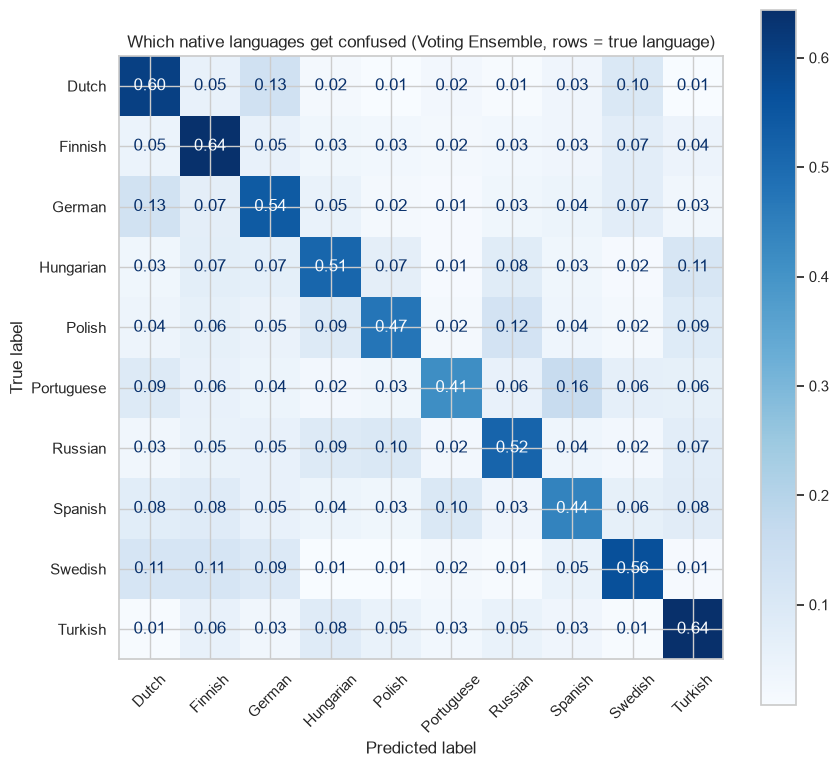

In [19]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    labels=languages,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)
ax.set_title(f"Which native languages get confused ({best_name}, rows = true language)")
plt.tight_layout()
plt.show()

In [20]:
# Most common mix-ups (off-diagonal cells), as a share of the true language.
cm = pd.crosstab(y_test, best_pred, normalize="index")
mixups = cm.stack().rename("share").reset_index()
mixups.columns = ["True language", "Predicted as", "Share"]
mixups = mixups[mixups["True language"] != mixups["Predicted as"]]
display(mixups.sort_values("Share", ascending=False).head(10).round(3))

,True language,Predicted as,Share
57,Portuguese,Spanish,0.158
2,Dutch,German,0.134
20,German,Dutch,0.128
46,Polish,Russian,0.124
81,Swedish,Finnish,0.113
80,Swedish,Dutch,0.113
39,Hungarian,Turkish,0.108
75,Spanish,Portuguese,0.101
64,Russian,Polish,0.101
8,Dutch,Swedish,0.099


**Result:** The most common mix-ups are between related languages: Portuguese → Spanish (16%), Dutch ↔ German (13%), Polish → Russian (12%), and Swedish → Dutch (11%). Swedish → Finnish (11%) is an exception across families, possibly reflecting shared education or geography. Turkish and Finnish are identified best; Portuguese and Spanish, the smallest classes, are hardest.

## 11. Error Analysis: Accuracy by Learner Skill
The model identifies native language from mistakes. Learners who make very few mistakes leave little to go on, so we expect accuracy to fall as overall score rises. We split the test set into four equal groups by overall score.

,Score range,Accuracy,Macro F1
Lowest 25%,0.48-0.87,0.642,0.583
25-50%,0.87-0.93,0.585,0.570
50-75%,0.93-0.97,0.534,0.502
Top 25%,0.97-1.00,0.470,0.377


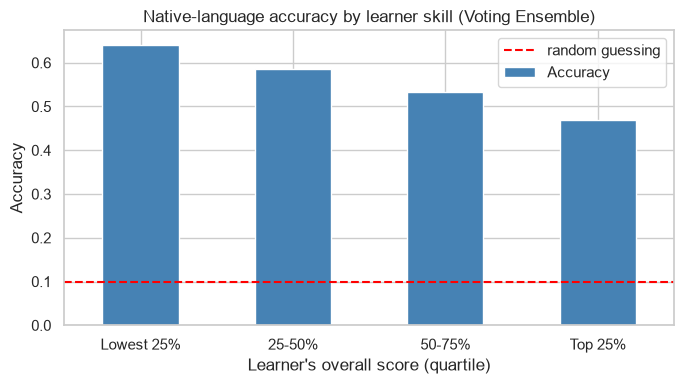

In [21]:
test_score = X_test[q_cols].mean(axis=1)
is_correct = pd.Series(best_pred == y_test.values, index=y_test.index)

skill_band = pd.qcut(test_score.rank(method="first"), 4,
                     labels=["Lowest 25%", "25-50%", "50-75%", "Top 25%"])

skill_df = pd.DataFrame({
    "Score range": test_score.groupby(skill_band, observed=True).agg(lambda s: f"{s.min():.2f}-{s.max():.2f}"),
    "Accuracy": is_correct.groupby(skill_band, observed=True).mean(),
    "Macro F1": [f1_score(y_test[skill_band == b], best_pred[(skill_band == b).values], average="macro")
                 for b in skill_band.cat.categories]
})
display(skill_df.round(3))

skill_df["Accuracy"].plot.bar(color="steelblue", figsize=(7, 4))
plt.axhline(0.1, color="red", ls="--", label="random guessing")
plt.ylabel("Accuracy")
plt.xlabel("Learner's overall score (quartile)")
plt.title(f"Native-language accuracy by learner skill ({best_name})")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

**Result:** As expected, accuracy falls from 64% for the lowest-scoring quarter to 47% for the top quarter (macro F1 0.58 → 0.38). Learners who make more mistakes give the model more to work with; near-native learners look alike regardless of native language. This explains much of why overall accuracy stays near 55%.

## 12. Feature Importance: Which Questions Reveal Native Language?
We use permutation importance on the best model: shuffle one question at a time and measure how much macro F1 drops. To keep this fast, we use a stratified sample of 10,000 test rows. Bars are colored by whether the question is one of the 95 scored questions or one of the 37 extra ones.

Permutation importance took 80s


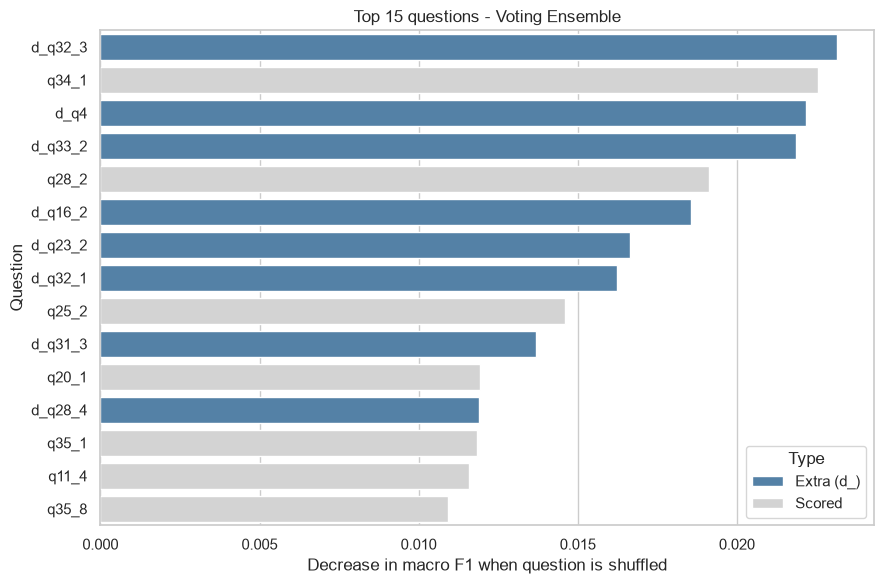

Extra (d_) questions in the top 15: 8


In [22]:
X_imp, _, y_imp, _ = train_test_split(
    X_test, y_test,
    train_size=10_000,
    random_state=RANDOM_STATE,
    stratify=y_test
)

start = time.time()
importance = permutation_importance(
    best_model,
    X_imp,
    y_imp,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=2   # kept low so large ensembles aren't copied to every CPU core at once
)
print(f"Permutation importance took {time.time() - start:.0f}s")

importance_df = pd.DataFrame({
    "Question": X_imp.columns,
    "Importance": importance.importances_mean,
    "Type": ["Extra (d_)" if c.startswith("d_") else "Scored" for c in X_imp.columns]
}).sort_values(by="Importance", ascending=False)

top_features = importance_df.head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x="Importance", y="Question", hue="Type",
            dodge=False, palette={"Extra (d_)": "steelblue", "Scored": "lightgray"})
plt.title(f"Top 15 questions - {best_name}")
plt.xlabel("Decrease in macro F1 when question is shuffled")
plt.ylabel("Question")
plt.tight_layout()
plt.show()

print("Extra (d_) questions in the top 15:", (top_features["Type"] == "Extra (d_)").sum())

**Result:** 8 of the 15 most important questions are extra (`d_`) questions, even though they are only 37 of the 132 features. This matches Section 9a: the questions native speakers disagree on drive most of the model's ability to identify native language.

### Language signatures from logistic regression
Logistic regression learns one weight per question per language. A large positive weight means answering that question in the native-majority way makes that language **more** likely; a large negative weight means a "non-native" answer on that question points toward that language. Below are the three most telling questions in each direction for each language.

In [23]:
lr = final_models["Logistic Regression"]
coef = pd.DataFrame(lr.coef_, index=lr.classes_, columns=X_train.columns)

signatures = pd.DataFrame({
    "Most negative (non-native answer points here)": coef.apply(lambda r: ", ".join(r.nsmallest(3).index), axis=1),
    "Most positive (native-like answer points here)": coef.apply(lambda r: ", ".join(r.nlargest(3).index), axis=1)
})
display(signatures)

,Most negative (non-native answer points here),Most positive (native-like answer points here)
Dutch,"q26_3, d_q28_4, q3","d_q32_3, q35_1, q27_4"
Finnish,"q28_2, q25_4, q28_1","q34_1, q20_1, q27_1"
German,"q18_2, q3, q20_2","q25_4, q22_2, q35_1"
Hungarian,"q28_1, q20_1, q19_2","q25_2, q26_2, q30_3"
Polish,"q20_1, q24_3, d_q4","q20_3, q28_2, d_q32_4"
Portuguese,"q16_4, q35_4, q27_1","q14_3, q27_2, q25_1"
Russian,"q34_1, d_q4, q25_4","q28_2, q13_4, q23_3"
Spanish,"q20_1, d_q16_2, q11_3","q28_2, q19_2, q34_3"
Swedish,"q28_2, q19_4, q26_2","q31_1, q11_4, q24_2"
Turkish,"q35_8, q26_4, q24_1","q28_2, q26_3, q10_4"


**Result:** Each language has its own set of telling questions, and the extra (`d_`) questions appear for several languages (e.g. Dutch, Polish, Russian, Spanish). These coefficient patterns show that the model is not just measuring skill; specific questions point toward specific languages.

## 13. Extension: Predicting Language Family
The confusion matrix shows which individual languages get mixed up. Here we ask a broader question: can the model at least tell which **language family** a learner comes from? We group the 10 languages into 5 families and retrain the tuned gradient boosting model (one of the two strongest single models, and faster to retrain than the ensemble).

native_lang
Uralic      49437
Germanic    46775
Slavic      32977
Turkic      28856
Romance     20585
Name: count, dtype: int64

Family baseline (most frequent) accuracy: 0.277
Family accuracy: 0.643 | macro F1: 0.634


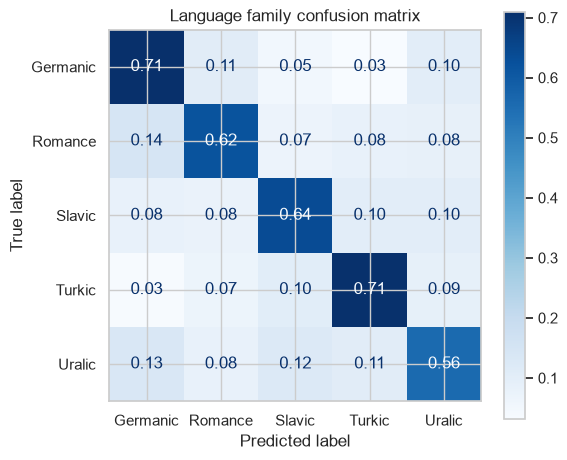

In [24]:
family = {
    "Finnish": "Uralic", "Hungarian": "Uralic",
    "Turkish": "Turkic",
    "German": "Germanic", "Dutch": "Germanic", "Swedish": "Germanic",
    "Russian": "Slavic", "Polish": "Slavic",
    "Spanish": "Romance", "Portuguese": "Romance"
}
yf_train, yf_test = y_train.map(family), y_test.map(family)
print(yf_train.value_counts())

family_model = clone(best_models["Gradient Boosting"]).fit(X_train, yf_train)
family_pred = family_model.predict(X_test)

family_baseline = yf_test.value_counts(normalize=True).max()
print(f"\nFamily baseline (most frequent) accuracy: {family_baseline:.3f}")
print(f"Family accuracy: {accuracy_score(yf_test, family_pred):.3f} | macro F1: {f1_score(yf_test, family_pred, average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yf_test, family_pred, normalize="true", values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("Language family confusion matrix")
plt.tight_layout()
plt.show()

**Result:** Predicting the language family is easier: 64.3% accuracy and 0.634 macro F1, against a 27.7% baseline. Combined with the confusion matrix, this shows that much of the remaining error is between closely related languages.

## 13b. Follow-up: Only Languages with More Than 20,000 Learners
To see how much the number of (and similarity between) languages affects performance, we repeat the task using only the five languages with more than 20,000 learners: Finnish, Turkish, German, Russian, and Hungarian. We filter the existing train/test split, so the same learners are used, and retrain the tuned gradient boosting model and the voting ensemble.

Languages kept: ['Finnish', 'Turkish', 'German', 'Russian', 'Hungarian']
Training rows: 115961 | Test rows: 28991
Baseline (most frequent) accuracy: 0.274

Gradient Boosting: accuracy 0.692 | macro F1 0.678
Voting Ensemble: accuracy 0.696 | macro F1 0.680


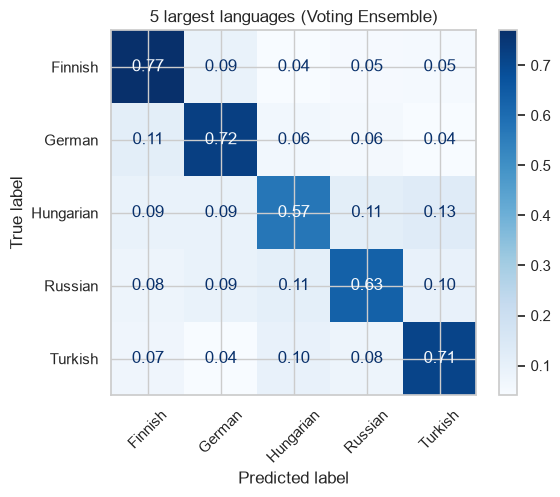

In [27]:
big = y.value_counts()[lambda s: s > 20_000].index.tolist()
print("Languages kept:", big)

tr, te = y_train.isin(big), y_test.isin(big)
Xb_train, yb_train = X_train[tr], y_train[tr]
Xb_test, yb_test = X_test[te], y_test[te]
print(f"Training rows: {len(Xb_train)} | Test rows: {len(Xb_test)}")

big_baseline = yb_test.value_counts(normalize=True).max()
print(f"Baseline (most frequent) accuracy: {big_baseline:.3f}\n")

big_models = {
    "Gradient Boosting": clone(best_models["Gradient Boosting"]),
    "Voting Ensemble": VotingClassifier(
        estimators=[(name, clone(best_models[name])) for name in top3],
        voting="soft", n_jobs=-1),
}
for name, model in big_models.items():
    model.fit(Xb_train, yb_train)
    p = model.predict(Xb_test)
    print(f"{name}: accuracy {accuracy_score(yb_test, p):.3f} | macro F1 {f1_score(yb_test, p, average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yb_test, big_models["Voting Ensemble"].predict(Xb_test),
    normalize="true", values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("5 largest languages (Voting Ensemble)")
plt.tight_layout(); plt.show()

**Result:** With only the five languages that have more than 20,000 learners, the voting ensemble reaches 69.6% accuracy and 0.680 macro F1 (baseline 27.4%), compared with 55.8% and 0.531 for all ten languages. Most of this gain comes from the easier task: there are fewer classes, and the closely related pairs that caused the most confusion (Dutch/German, Spanish/Portuguese, Polish/Russian) are no longer both present. Relative to its baseline, the ten-language model performs about as well or better (about 3.1× vs. 2.5× the baseline accuracy), so the higher score mainly reflects a simpler question rather than a stronger model.

## 14. Summary
- **Every model clearly beats the baseline**, so grammar answers do carry information about a learner's native language. Always guessing Finnish gets 17.8% accuracy and 0.030 macro F1; random guessing among 10 languages would get about 10%.
- **Best model:** the soft-voting ensemble (MLP + gradient boosting + logistic regression), with **macro F1 of 0.531** and **accuracy of 55.8%** on the test set. The MLP alone (0.527) and gradient boosting alone (0.523) were close behind, so ensembling added only a small gain. Naive Bayes was the weakest model (0.396), likely because it assumes every question is independent given the language.
- **The 37 extra questions matter most.** Adding the grammar decisions that native speakers disagree on raised macro F1 from 0.380 to 0.494 for logistic regression and from 0.397 to 0.523 for gradient boosting. 12 of the 20 questions that differ most between languages, and 8 of the 15 most important questions for the best model, are extra (`d_`) questions. These items reflect usage and dialect rather than clear right/wrong grammar, so learners' answers on them carry traces of their first language.
- **Adding skill information did not help** (Section 9b): adding the overall score or skill-adjusting the answers changed cross-validated macro F1 by less than 0.01, so the models already account for overall skill.
- **Confusions follow language families.** The most common mix-ups were Portuguese → Spanish (16%), Dutch ↔ German (13%), Polish → Russian (12%), and Swedish → Dutch (11%). Turkish (F1 0.667) and Finnish (0.658) were easiest to identify; Portuguese (0.418) and Spanish (0.437) were hardest, since they are the smallest classes and are mostly confused with each other.
- **Language family is easier to predict:** grouping the 10 languages into 5 families gives 64.3% accuracy and 0.634 macro F1 (baseline 27.7%).
- **Fewer, less similar languages are easier:** using only the five languages with more than 20,000 learners raises accuracy to 69.6% and macro F1 to 0.680 (baseline 27.4%), mainly because related language pairs are removed.
- **Limitation:** accuracy falls from 64% for the lowest-scoring quarter of learners to 47% for the top quarter (macro F1 0.58 → 0.38), because near-native learners make few mistakes for the model to use.